# 04 · Définition de la cible

**Question métier** : chaque soir, quelles bornes risquent un **épisode anormal de défauts matériels** le lendemain ?

Ce notebook choisit, chiffres et graphiques à l'appui, ce qu'est un « épisode anormal ». Le choix est guidé par quatre critères fixés **avant** de regarder les résultats, pour ne pas choisir la définition qui arrange :

| Critère | Pourquoi |
|---|---|
| Entre 5 et 15 % de jours positifs | Assez d'exemples pour apprendre, assez rare pour rester une alerte |
| Positifs répartis sur la plupart des bornes | Sinon, le modèle ne ferait que désigner quelques bornes chroniquement mauvaises |
| Stabilité dans le temps | Une cible dont la fréquence varie fortement est plus difficile à apprendre et à surveiller |
| Au moins 2 défauts par épisode | Un défaut isolé ne justifie pas de déplacer un technicien |

Un cinquième regard compte : la **persistance**. Si un épisode aujourd'hui annonce presque toujours un épisode demain, la règle « inspecter les bornes en épisode aujourd'hui » suffit, et le modèle n'apporte rien.

In [10]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from evrel.data.clean import load_interim
from evrel.data.load import get_data_dir, load_config
from evrel.target import (add_hardware_fault, add_past_baseline, daily_post_table,
                          hardware_causes, label_episodes)
from evrel.viz import INK_2, NEUTRAL, PALETTE, set_style

set_style()
sessions = load_interim()
window = load_config()["target"]["episode"]["baseline_window_days"]
daily = add_past_baseline(daily_post_table(add_hardware_fault(sessions, hardware_causes())), window=window)
observable = daily[daily["n_sessions"] > 0]
print(f"Jours-bornes : {len(daily):,}, dont {len(observable):,} avec au moins une session")

Jours-bornes : 66,698, dont 57,222 avec au moins une session


## 1. À quoi ressemble une journée de borne ?

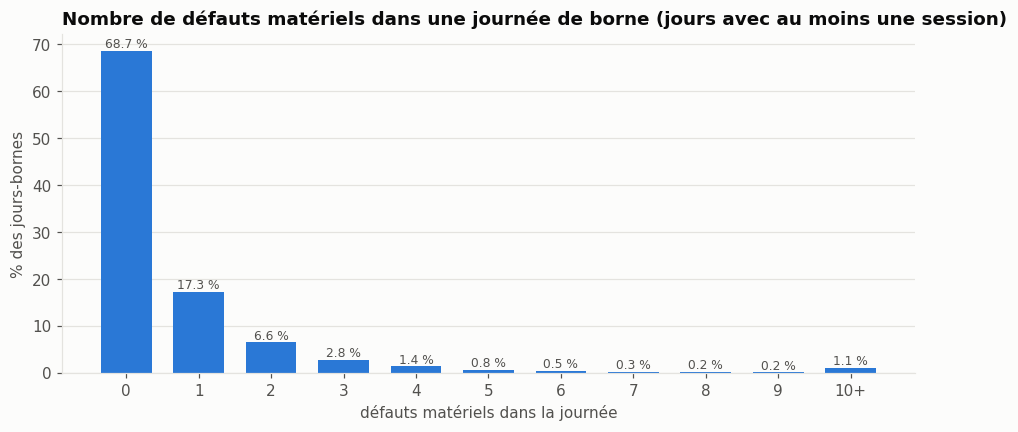

,n_sessions,n_hw_faults,hw_fault_rate,baseline_rate
count,57222.000,57222.000,57222.000,56673.000
mean,7.708,0.784,0.089,0.098
std,5.527,2.401,0.195,0.132
min,1.000,0.000,0.000,0.000
25%,3.000,0.000,0.000,0.023
50%,7.000,0.000,0.000,0.056
75%,11.000,1.000,0.100,0.118
max,72.000,60.000,1.000,1.000


In [11]:
counts = observable["n_hw_faults"].clip(upper=10).value_counts().sort_index()
share = counts / counts.sum() * 100

fig, ax = plt.subplots()
ax.bar([str(i) if i < 10 else "10+" for i in counts.index], share.values, color=PALETTE[0], width=0.7)
for x, v in enumerate(share.values):
    ax.text(x, v, f"{v:.1f} %", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_title("Nombre de défauts matériels dans une journée de borne (jours avec au moins une session)")
ax.set_xlabel("défauts matériels dans la journée")
ax.set_ylabel("% des jours-bornes")
ax.grid(axis="x", visible=False)
plt.show()

observable[["n_sessions", "n_hw_faults", "hw_fault_rate", "baseline_rate"]].describe().round(3)

**Constat** : sur 57 222 jours-bornes avec au moins une session (sur 66 698 au total), 68,7 % n'ont aucun défaut matériel, 17,3 % en ont un seul et 6,6 % en ont deux. La distribution a une longue traîne : 1,1 % des jours comptent 10 défauts ou plus, et le maximum atteint 60 défauts en une journée. Une borne fait en moyenne 7,7 sessions par jour.


## 2. Les définitions candidates

Chaque candidat combine un **nombre minimal de défauts** dans la journée et, éventuellement, un **taux au moins k fois supérieur au niveau habituel** de la borne (calculé sur les 28 jours précédents, jour exclu).

In [12]:
CANDIDATES = {
    "A · ≥1 défaut":            dict(min_faults=1),
    "B · ≥2 défauts":           dict(min_faults=2),
    "C · ≥3 défauts":           dict(min_faults=3),
    "D · ≥2 défauts et ≥2× l'habituel": dict(min_faults=2, min_ratio=2),
    "E · ≥2 défauts et ≥3× l'habituel": dict(min_faults=2, min_ratio=3),
    "F · ≥3 défauts et ≥2× l'habituel": dict(min_faults=3, min_ratio=2),
}

labels = {name: label_episodes(daily, **params)["is_episode"] for name, params in CANDIDATES.items()}
quarter = daily["date"].dt.to_period("Q")

rows = []
for name, y in labels.items():
    obs = y.notna()
    pos = y.eq(1)
    by_post = pos.groupby(daily["post_id"]).sum().sort_values(ascending=False)
    by_q = pos[obs].groupby(quarter[obs]).mean() * 100
    nxt = y.groupby(daily["post_id"]).shift(-1)          # même borne, jour suivant
    persist = nxt[pos & nxt.notna()].eq(1).mean() * 100
    rows.append({
        "définition": name,
        "jours observables": int(obs.sum()),
        "positifs": int(pos.sum()),
        "taux %": round(pos[obs].mean() * 100, 2),
        "bornes avec ≥1 positif": int((by_post > 0).sum()),
        "part des 10 bornes les plus touchées %": round(by_post.head(10).sum() / max(pos.sum(), 1) * 100, 1),
        "écart-type trimestriel (points)": round(by_q.std(), 2),
        "persistance J→J+1 %": round(persist, 1),
    })
summary = pd.DataFrame(rows).set_index("définition")
summary

,jours observables,positifs,taux %,bornes avec ≥1 positif,part des 10 bornes les plus touchées %,écart-type trimestriel (points),persistance J→J+1 %
définition,,,,,,,
A · ≥1 défaut,57222,17916,31.31,92,23.0,7.38,53.0
B · ≥2 défauts,57222,8034,14.04,92,31.8,4.40,42.6
C · ≥3 défauts,57222,4266,7.46,91,37.4,2.66,41.0
D · ≥2 défauts et ≥2× l'habituel,56673,4160,7.34,92,21.4,1.64,23.3
E · ≥2 défauts et ≥3× l'habituel,56673,2623,4.63,92,19.9,0.76,18.6
F · ≥3 défauts et ≥2× l'habituel,56673,2300,4.06,91,28.7,1.21,25.4


Comment lire le tableau :
- **taux %** : part des jours observables qui sont des épisodes.
- **part des 10 bornes les plus touchées** : si elle est très élevée, la cible se résume à quelques bornes chroniques.
- **écart-type trimestriel** : plus il est faible, plus la fréquence de la cible est stable dans le temps.
- **persistance** : probabilité qu'un épisode soit suivi d'un autre le lendemain sur la même borne. À comparer au taux de base.

## 3. Lesquelles respectent les critères ?

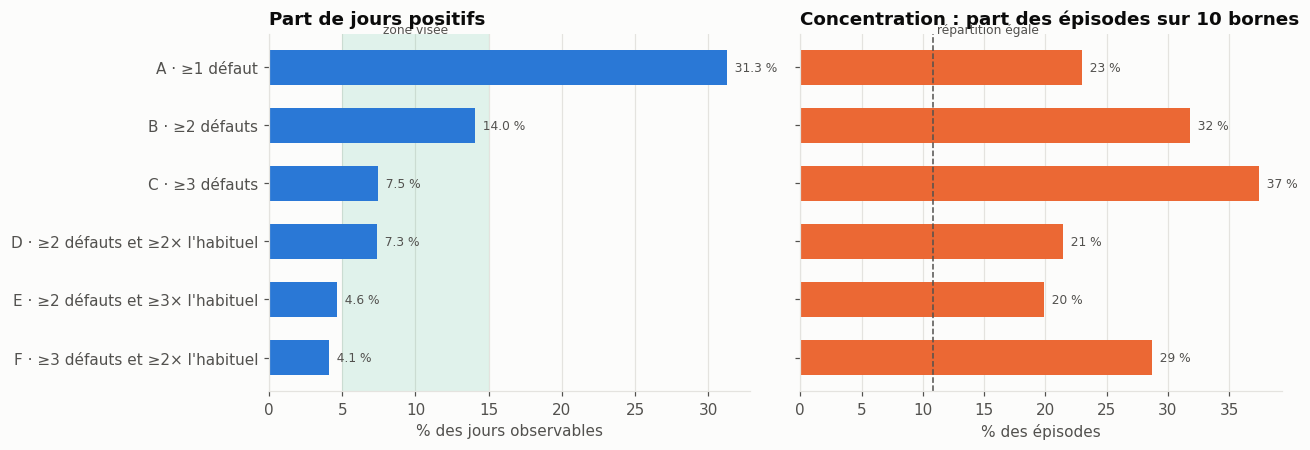

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
names = summary.index[::-1]

ax = axes[0]
ax.axvspan(5, 15, color=PALETTE[2], alpha=0.12, lw=0)
ax.text(10, len(names) - 0.4, "zone visée", ha="center", fontsize=8, color=INK_2)
ax.barh(names, summary.loc[names, "taux %"], color=PALETTE[0], height=0.6)
for y, v in enumerate(summary.loc[names, "taux %"]):
    ax.text(v, y, f"  {v:.1f} %", va="center", fontsize=8, color=INK_2)
ax.set_title("Part de jours positifs")
ax.set_xlabel("% des jours observables")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(names, summary.loc[names, "part des 10 bornes les plus touchées %"], color=PALETTE[1], height=0.6)
ax.axvline(10 / daily["post_id"].nunique() * 100, color=INK_2, lw=1, ls="--")
ax.text(10 / daily["post_id"].nunique() * 100, len(names) - 0.4, " répartition égale", fontsize=8, color=INK_2)
for y, v in enumerate(summary.loc[names, "part des 10 bornes les plus touchées %"]):
    ax.text(v, y, f"  {v:.0f} %", va="center", fontsize=8, color=INK_2)
ax.set_title("Concentration : part des épisodes sur 10 bornes")
ax.set_xlabel("% des épisodes")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Constat** : A (31,3 %) est trop fréquent pour être une alerte. B (14,0 %) et C (7,5 %) sont dans la zone visée mais concentrent respectivement 32 % et 37 % de leurs épisodes sur 10 bornes : les règles absolues désignent surtout les bornes chroniquement mauvaises. Les règles relatives D et E concentrent moins (21 % et 20 %), avec des épisodes répartis sur les 92 bornes. E (4,6 %) et F (4,1 %) passent sous la barre des 5 %.


## 4. Stabilité dans le temps

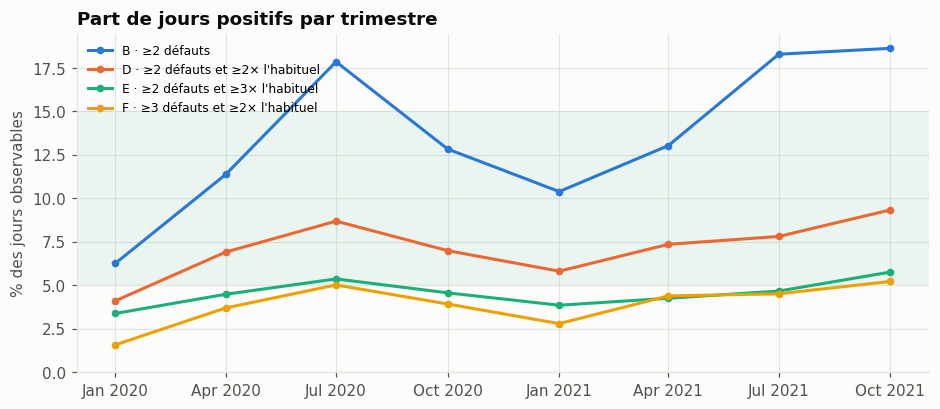

In [14]:
keep = [n for n in CANDIDATES if n[0] in "BDEF"]
fig, ax = plt.subplots()
for i, name in enumerate(keep):
    y = labels[name]
    obs = y.notna()
    q = y[obs].eq(1).groupby(daily.loc[obs, "date"].dt.to_period("Q")).mean() * 100
    ax.plot(q.index.to_timestamp(), q.values, marker="o", ms=4, color=PALETTE[i], label=name)
ax.axhspan(5, 15, color=PALETTE[2], alpha=0.08, lw=0)
ax.set_title("Part de jours positifs par trimestre")
ax.set_ylabel("% des jours observables")
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

**Constat** : B varie de 6,3 % à 18,6 % selon les trimestres : une règle absolue suit la croissance du volume. D est nettement plus stable (écart-type de 1,64 point), mais monte progressivement de 4,1 % au premier trimestre 2020 à 9,3 % au dernier trimestre 2021. E est la plus stable (0,76 point).


## 5. Persistance : le problème est-il trivial ?

Si la persistance est proche de 100 %, « inspecter les bornes en épisode aujourd'hui » suffit. Si elle est proche du taux de base, un épisode n'annonce rien pour le lendemain, et la prédiction sera très difficile. **Le cas intéressant est entre les deux.**

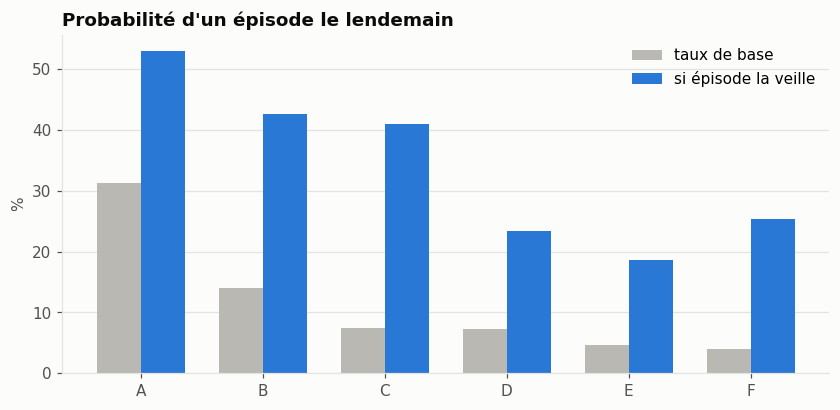

,taux %,persistance J→J+1 %,gain vs hasard (×)
définition,,,
A · ≥1 défaut,31.31,53.0,1.7
B · ≥2 défauts,14.04,42.6,3.0
C · ≥3 défauts,7.46,41.0,5.5
D · ≥2 défauts et ≥2× l'habituel,7.34,23.3,3.2
E · ≥2 défauts et ≥3× l'habituel,4.63,18.6,4.0
F · ≥3 défauts et ≥2× l'habituel,4.06,25.4,6.3


In [15]:
persist = summary[["taux %", "persistance J→J+1 %"]].copy()
persist["gain vs hasard (×)"] = (persist["persistance J→J+1 %"] / persist["taux %"]).round(1)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(persist))
ax.bar(x - 0.18, persist["taux %"], width=0.36, color=NEUTRAL, label="taux de base")
ax.bar(x + 0.18, persist["persistance J→J+1 %"], width=0.36, color=PALETTE[0], label="si épisode la veille")
ax.set_xticks(x)
ax.set_xticklabels([n.split(" · ")[0] for n in persist.index])
ax.set_title("Probabilité d'un épisode le lendemain")
ax.set_ylabel("%")
ax.legend()
ax.grid(axis="x", visible=False)
plt.show()
persist

**Constat** : pour D, une borne en épisode a 23,3 % de chances d'en avoir un autre le lendemain, contre 7,3 % en temps normal (3,2 fois plus). Les règles absolues sont bien plus persistantes (42,6 % pour B, 41,0 % pour C), car elles désignent des bornes chroniquement mauvaises, en problème jour après jour.


## 6. Vérification visuelle sur une borne

Un chiffre ne suffit pas : on regarde à quoi ressemblent les épisodes sur la borne qui en compte le plus, pour vérifier qu'ils correspondent bien à ce qu'un exploitant appellerait « un problème ».

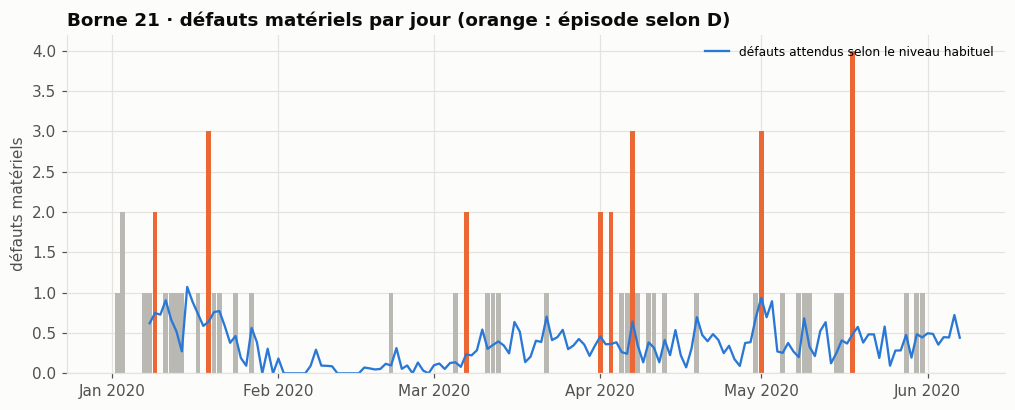

In [16]:
CHOSEN_FOR_PLOT = "D · ≥2 défauts et ≥2× l'habituel"   # à changer pour comparer
y = labels[CHOSEN_FOR_PLOT]
post = y.eq(1).groupby(daily["post_id"]).sum().idxmax()
d = daily.assign(is_episode=y)[daily["post_id"] == post]
start = d.loc[d["is_episode"].eq(1), "date"].min() - pd.Timedelta(days=30)   # fenêtre autour des épisodes
d = d[d["date"].between(start, start + pd.Timedelta(days=180))]

fig, ax = plt.subplots(figsize=(11, 4))
colors = np.where(d["is_episode"].eq(1), PALETTE[1], NEUTRAL)
ax.bar(d["date"], d["n_hw_faults"], color=colors, width=0.9)
ax.plot(d["date"], d["baseline_rate"] * d["n_sessions"], color=PALETTE[0], lw=1.5,
        label="défauts attendus selon le niveau habituel")
ax.set_title(f"Borne {post} · défauts matériels par jour (orange : épisode selon {CHOSEN_FOR_PLOT.split(' · ')[0]})")
ax.set_ylabel("défauts matériels")
ax.legend(loc="upper right", fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

**Constat** : sur la borne 21, la plus touchée selon D, les épisodes sont des jours à 2 à 4 défauts alors que son niveau habituel en prévoit environ 0,5. Ils sont le plus souvent isolés. Les jours à 2 défauts de début janvier 2020 ne sont pas marqués, car la borne n'a pas encore 7 jours d'historique : ils sont non observables.


## 7. Décision



**Définition retenue : D.** Un jour est un épisode anormal pour une borne si elle enregistre **au moins 2 défauts matériels** et un **taux de défauts au moins 2 fois supérieur à son niveau habituel** (calculé sur les 28 jours précédents, jour exclu, avec au moins 7 jours d'historique).

| Critère | Résultat de D | Respecté |
|---|---|---|
| 5 à 15 % de jours positifs | 7,34 % (4 160 épisodes sur 56 673 jours observables) | Oui |
| Répartition sur les bornes | 92 bornes sur 92, 21,4 % des épisodes sur les 10 plus touchées | Oui |
| Stabilité | Écart-type trimestriel de 1,64 point | Oui, avec une hausse à surveiller |
| Au moins 2 défauts | Par construction | Oui |

**Test de sensibilité prévu** : E (au moins 3 fois le niveau habituel, 4,63 % de positifs), pour vérifier que les conclusions du modèle ne dépendent pas d'un seuil précis.

Paramètres reportés dans `configs/config.yaml` : `min_faults: 2`, `min_ratio: 2`.

In [17]:
params = load_config()["target"]["episode"]
if params["min_faults"] is None:
    print("Décision pas encore reportée dans config.yaml : rien n'est écrit.")
else:
    final = label_episodes(daily, params["min_faults"], params["min_ratio"])
    out = get_data_dir() / "processed" / "daily_target.parquet"
    out.parent.mkdir(parents=True, exist_ok=True)
    final.to_parquet(out, index=False)
    obs = final["is_episode"].notna()
    print(f"Écrit : {out}")
    print(f"{obs.sum():,} jours observables, {int(final['is_episode'].eq(1).sum()):,} épisodes "
          f"({final.loc[obs, 'is_episode'].mean() * 100:.2f} %)")

Écrit : C:\dev\ev-reliability-data\processed\daily_target.parquet
56,673 jours observables, 4,160 épisodes (7.34 %)


## Ce qu'on retient

- **La cible est définie** : au moins 2 défauts matériels et un taux au moins 2 fois supérieur au niveau habituel de la borne. 4 160 épisodes, soit 7,34 % des jours observables.
- **La définition relative bat l'absolue** : elle répartit les épisodes sur tout le parc (21 % sur 10 bornes, contre 37 % pour « au moins 3 défauts ») et elle est plus stable dans le temps.
- **Le problème vaut un modèle** : un épisode aujourd'hui annonce un épisode demain dans 23,3 % des cas seulement. La règle de bon sens est utile mais insuffisante.
- **Un risque identifié** : la fréquence des épisodes monte de 4,1 % à 9,3 % entre début 2020 et fin 2021. À surveiller en production.
- Les critères de choix ont été fixés avant de calculer les résultats.